https://karpathy.github.io/2026/02/12/microgpt/

In [14]:
from gpt_data import *

In [10]:
for x in Yval[:13]:
	name = ""
	for l in x:
		if l == 26:
			name += "."
			continue
		name += chr(l + ord('a'))
	print(name)

..zaylyn
.zaylynn
zaylynn.
.......z
......ze
.....zen
....zeno
...zenob
..zenobi
.zenobia
zenobia.
.......a
......ad


In [ ]:
class SingleAttention(nn.Module):
	def __init__(self, embedding_size=64):
		super().__init__()

		self.B, self.T, self.C = batchsize, context_size, embedding_size

		self.embeddings = nn.Embedding(27, self.C)
		self.pos = nn.Embedding(self.T, self.C) 

		# Q what this position looks for
		# K what this position offers
		# V creates an embedding of current token and how much attention it'll receive
		self.Q, self.K, self.V = nn.Linear(self.C, self.C), nn.Linear(self.C, self.C), nn.Linear(self.C, self.C)

		# lower triangular
		self.trimask = torch.tril(torch.ones(self.T, self.T)).log()

		self.mlp = nn.Sequential(
			nn.Linear(self.C, self.C*4),
			nn.ReLU(),
			nn.Linear(self.C*4, self.C),
			nn.Dropout(0.1)
		)

		self.ln1 = nn.LayerNorm(self.C)
		self.ln2 = nn.LayerNorm(self.C)
		self.ln_f = nn.LayerNorm(self.C)

		self.head = nn.Linear(self.C, 27)
	
	def attn(self, x):
		# Q, K, V are size (C, d==C)
		# only d == C. look at macrogpt for d != C 

		# emb @ weights
		q, k, v = self.Q(x), self.K(x), self.V(x)

		# cosine sim with query * key
		# what this sequence is looking for * what this sequence offers
		scores = q @ k.mT / self.C**0.5

		# triangular mask
		scores += self.trimask

		att = torch.softmax(scores, dim=-1)
		return att @ v

	def forward(self, tokens):
		tok_emb, pos_emb = self.embeddings(tokens), self.pos(torch.arange(self.T))
		x = tok_emb + pos_emb            # (B, T, C)

		# one block
		x = x + self.attn(self.ln1(x))         # residual, all positions
		x = x + self.mlp(self.ln2(x))

		logits = self.head(self.ln_f(x)) 
		return logits

mymodel = SingleAttention()

In [24]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(mymodel.parameters()) 

lossi = []

for i in range(100000):
	ixs = torch.randint(0, Xtrain.shape[0], (batchsize,))
	ctx, target = Xtrain[ixs], Ytrain[ixs]

	logits = mymodel(ctx)

	loss = criterion(logits.mT, target)

	optimizer.zero_grad()
	loss.backward()
	optimizer.step()

	lossi.append(loss.item())

print(loss.item())

1.0083709955215454


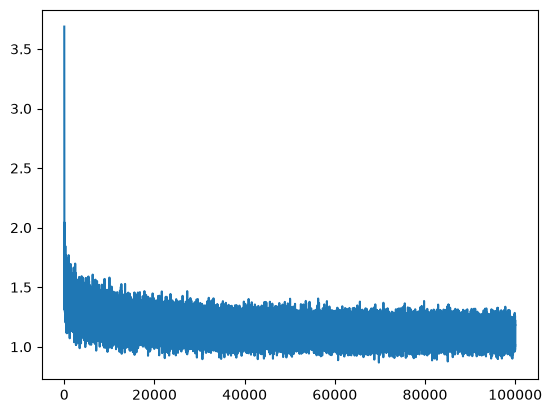

In [28]:
plt.plot(lossi)

In [30]:
alpha = "abcdefghijklmnopqrstuvwxyz."

mymodel.eval() 

for i in range(20):
	ctx = torch.tensor([26] * context_size).unsqueeze(0)
	name = ""

	while len(name) < 20:
		logits = mymodel(ctx)
		probs = torch.softmax(logits[:, -1, :], axis=1)
		cidx = torch.multinomial(probs, 1)
		c = alpha[cidx.item()]; name += c
		if c == ".":
			break
		ctx = torch.cat([ctx[:, 1:], cidx], dim=1)
	
	print(name)

evanna.
judil.
kallioper.
adaliyah.
josephineva.
paignel.
weslynn.
presleigh.
heidi.
lillianne.
shaina.
rowan.
anabel.
lina.
paizley.
paula.
ara.
lucianna.
olivia.
kourtney.


In [27]:
@torch.no_grad()
def get_loss(split):
	X, Y = {
		"train": (Xtrain, Ytrain),
		"val": (Xval, Yval)
	}[split]

	ixs = torch.randint(0, X.shape[0], (batchsize,))
	ctx, target = X[ixs], Y[ixs]

	logits = mymodel(ctx)
	loss = F.cross_entropy(logits.view(-1, 27), target.view(-1))

	print(split, loss.item())

get_loss("train")
get_loss("val")

train 1.0556772947311401
val 1.5466749668121338
